In [1]:
import numpy as np 
import pandas as pd 
import os
import random
import torch 
import torchvision
from torch import nn
from  torchvision import datasets
from torchvision.transforms import ToTensor
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms


import matplotlib.pyplot as plt



In [2]:
device = 'cuda' if torch.cuda.is_available() else "cpu"
print(torch.cuda.device_count())

2


In [3]:
cifar_path = '/kaggle/input/datasets/mariamtobar/cifar10-custom'

In [4]:
SEED = 42

mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)


train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])


train_full = datasets.CIFAR10(
    root=cifar_path,
    train=True,
    download=True,
    transform=train_transform
)

val_full = datasets.CIFAR10(
    root=cifar_path,
    train=True, 
    download=True,
    transform=eval_transform
)


generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(len(train_full), generator=generator).tolist()

train_indices = indices[:45000]
val_indices = indices[45000:]

train_dataset = Subset(train_full, train_indices)
val_dataset = Subset(val_full, val_indices)

print("Full training dataset:", len(train_full))
print("Full validation source:", len(val_full))
print("Training subset:", len(train_dataset))
print("Validation subset:", len(val_dataset))

assert len(train_full) == 50000
assert len(val_full) == 50000
assert max(train_indices) < len(train_full)
assert max(val_indices) < len(val_full)


Full training dataset: 50000
Full validation source: 50000
Training subset: 45000
Validation subset: 5000


In [5]:
image,label = train_data[0]
image,label

(tensor([[[-1.0527e+00, -1.3068e+00, -1.1956e+00,  ...,  5.1906e-01,
            4.2380e-01,  3.6029e-01],
          [-1.7354e+00, -1.9895e+00, -1.7037e+00,  ..., -3.6628e-02,
           -1.0013e-01, -5.2505e-02],
          [-1.5926e+00, -1.7354e+00, -1.2115e+00,  ..., -1.1601e-01,
           -8.4258e-02, -2.5890e-01],
          ...,
          [ 1.3129e+00,  1.2018e+00,  1.1541e+00,  ...,  5.5081e-01,
           -1.1004e+00, -1.1480e+00],
          [ 8.6835e-01,  7.5721e-01,  9.6361e-01,  ...,  9.3186e-01,
           -4.4942e-01, -6.7170e-01],
          [ 8.2072e-01,  6.7783e-01,  8.5247e-01,  ...,  1.4399e+00,
            4.0792e-01, -3.6628e-02]],
 
         [[-9.8178e-01, -1.2395e+00, -1.2072e+00,  ...,  1.4557e-01,
            3.2838e-02,  1.6733e-02],
          [-1.6582e+00, -1.9803e+00, -1.8514e+00,  ..., -5.6305e-01,
           -6.4357e-01, -5.7915e-01],
          [-1.5938e+00, -1.8676e+00, -1.5455e+00,  ..., -6.2747e-01,
           -6.2747e-01, -8.0462e-01],
          ...,
    

In [6]:
train_data.classes

['airplane',
 'automobile',
 'bird',
 'cat',
 'deer',
 'dog',
 'frog',
 'horse',
 'ship',
 'truck']

In [7]:
image.shape

torch.Size([3, 32, 32])

In [8]:
len(train_data),len(test_data)

(50000, 10000)

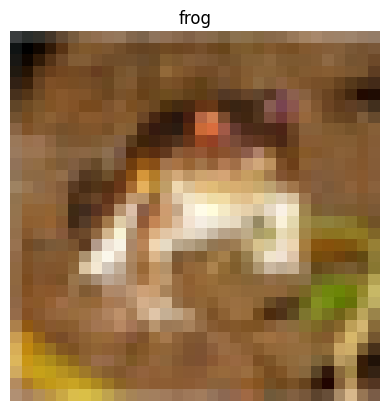

In [9]:
image_np = image.permute(1, 2, 0).numpy()


mean = np.array([0.4914, 0.4822, 0.4465])
std = np.array([0.2470, 0.2435, 0.2616])

#  Un-normalize the image: original = (normalized * std) + mean
denormalized_image = (image_np * std) + mean

#  Clip values to exactly [0, 1] to catch any tiny floating-point rounding errors
denormalized_image = np.clip(denormalized_image, 0, 1)

plt.imshow(denormalized_image)
plt.title(train_data.classes[label])
plt.axis('off')
plt.show()

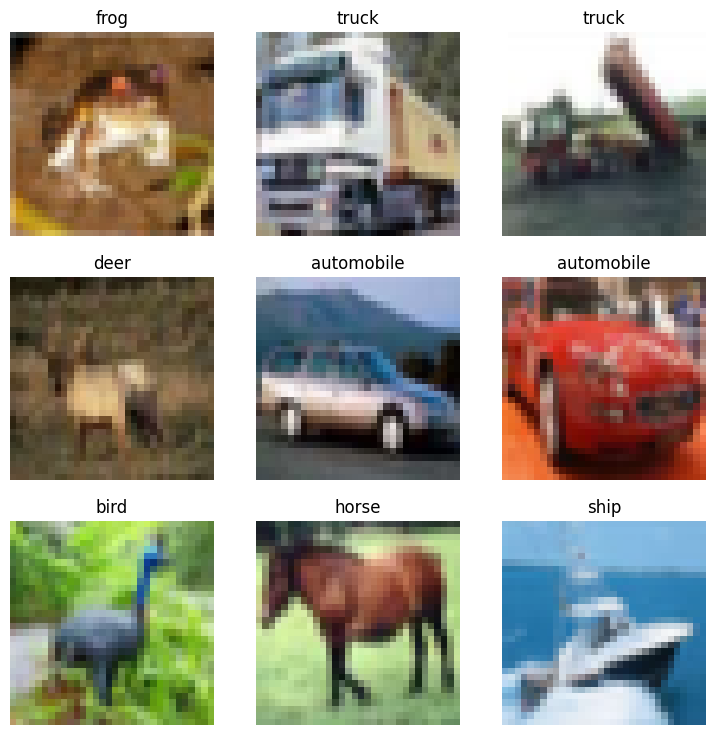

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(9, 9))

mean = torch.tensor((0.4914, 0.4822, 0.4465)).view(3, 1, 1)
std = torch.tensor((0.2470, 0.2435, 0.2616)).view(3, 1, 1)

for i, ax in enumerate(axes.flat):
    image, label = train_data[i]

    # Denormalize and strictly clamp values between 0 and 1
    image = image * std + mean
    image = torch.clamp(image, 0, 1)

    # Convert to NumPy for Matplotlib to avoid backend compatibility issues
    ax.imshow(image.permute(1, 2, 0).numpy())
    

    ax.set_title(train_data.classes[label])
    ax.axis('off')

plt.show()

# DataLoader

In [11]:

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)


train_images, train_labels = next(iter(train_loader))
val_images, val_labels = next(iter(val_loader))

print("Training batch:", train_images.shape, train_labels.shape)
print("Validation batch:", val_images.shape, val_labels.shape)





Training batch: torch.Size([128, 3, 32, 32]) torch.Size([128])
Validation batch: torch.Size([128, 3, 32, 32]) torch.Size([128])


In [12]:
images, labels = next(iter(train_loader))
print(images.shape)

torch.Size([128, 3, 32, 32])


In [13]:
model = nn.Sequential(
    nn.Conv2d( in_channels=3,
        out_channels=16,
        kernel_size=3,
        stride=1,
        padding=1,
        bias=False),
    
    nn.BatchNorm2d(16),
    nn.ReLU(),
    
    nn.Conv2d(in_channels=16,
        out_channels=16,
        kernel_size=3,
        stride=1,
        padding=1,
        bias=False),
    
    nn.BatchNorm2d(16)
)

In [14]:
x = torch.randn(4, 3, 32, 32)
output = model(x)

print("Input shape: ", x.shape)
print("Output shape:", output.shape)

Input shape:  torch.Size([4, 3, 32, 32])
Output shape: torch.Size([4, 16, 32, 32])


In [15]:
class BasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        # Main path: first convolution
        self.conv1 = nn.Conv2d(
            in_channels=in_channels,
            out_channels=out_channels,
            kernel_size=3,
            stride=stride,
            padding=1,
            bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)

        # Main path: second convolution
        self.conv2 = nn.Conv2d(
            in_channels=out_channels,
            out_channels=out_channels,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        # Shortcut path
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels=in_channels,
                    out_channels=out_channels,
                    kernel_size=1,
                    stride=stride,
                    bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        identity = x

        # Main path
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        # Shortcut path
        identity = self.shortcut(identity)

        # Residual addition and final activation
        out = out + identity
        out = self.relu(out)

        return out


In [16]:
# ---------------------------------------------------------
# Test A: Same channels (16 -> 16) and stride 1
# This triggers the nn.Identity() shortcut
# ---------------------------------------------------------
block_a = BasicBlock(in_channels=16, out_channels=16, stride=1)
x_a = torch.randn(4, 16, 32, 32) # Batch of 4 images, 16 channels, 32x32 size
y_a = block_a(x_a)

print("--- Test A: Identity Shortcut ---")
print("Input shape: ", x_a.shape)
print("Output shape:", y_a.shape)
print()

# ---------------------------------------------------------
# Test B: Different channels (16 -> 32) and stride 2
# This triggers the 1x1 Conv2d projection shortcut
# ---------------------------------------------------------
block_b = BasicBlock(in_channels=16, out_channels=32, stride=2)
x_b = torch.randn(4, 16, 32, 32) # Same input shape as before
y_b = block_b(x_b)

print("--- Test B: Projection Shortcut ---")
print("Input shape: ", x_b.shape)
print("Output shape:", y_b.shape)

--- Test A: Identity Shortcut ---
Input shape:  torch.Size([4, 16, 32, 32])
Output shape: torch.Size([4, 16, 32, 32])

--- Test B: Projection Shortcut ---
Input shape:  torch.Size([4, 16, 32, 32])
Output shape: torch.Size([4, 32, 16, 16])


In [17]:

import torch
import torch.nn as nn


class ResNet18(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        # Track the number of channels entering the next block
        self.in_channels = 64

        # 1. Stem: adapted for 32x32 CIFAR-10 images
        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=64,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=False
        )
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)

        # 2. Four stages, each containing two BasicBlocks
        self.layer1 = self._make_layer(
            out_channels=64, num_blocks=2, stride=1
        )
        self.layer2 = self._make_layer(
            out_channels=128, num_blocks=2, stride=2
        )
        self.layer3 = self._make_layer(
            out_channels=256, num_blocks=2, stride=2
        )
        self.layer4 = self._make_layer(
            out_channels=512, num_blocks=2, stride=2
        )

        # 3. Convert the final feature maps into 512 features
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))

        # 4. Predict one score for each CIFAR-10 class
        self.fc = nn.Linear(512, num_classes)

    def _make_layer(self, out_channels, num_blocks, stride):
        layers = []

        # The first block may change channels and spatial size
        layers.append(
            BasicBlock(
                in_channels=self.in_channels,
                out_channels=out_channels,
                stride=stride
            )
        )

        # Update the channel count for the next block
        self.in_channels = out_channels

        # Remaining blocks preserve channels and spatial size
        for _ in range(1, num_blocks):
            layers.append(
                BasicBlock(
                    in_channels=self.in_channels,
                    out_channels=out_channels,
                    stride=1
                )
            )

        return nn.Sequential(*layers)

    def forward(self, x):
        # Stem
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)

        # Residual stages
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        # Pool: (B, 512, 4, 4) -> (B, 512, 1, 1)
        x = self.avgpool(x)

        # Flatten: (B, 512, 1, 1) -> (B, 512)
        x = torch.flatten(x, 1)

        # Class scores: (B, 512) -> (B, 10)
        x = self.fc(x)

        return x


In [18]:
model = ResNet18(num_classes=10)

x = torch.randn(4, 3, 32, 32)

model.eval()

with torch.no_grad():
    output = model(x)

print("Input shape:", x.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([4, 3, 32, 32])
Output shape: torch.Size([4, 10])


In [19]:
model.eval()
x = torch.randn(4, 3, 32, 32)

with torch.no_grad():
    x = model.conv1(x)
    x = model.bn1(x)
    x = model.relu(x)
    print("Stem:", x.shape)

    x = model.layer1(x)
    print("Stage 1:", x.shape)

    x = model.layer2(x)
    print("Stage 2:", x.shape)

    x = model.layer3(x)
    print("Stage 3:", x.shape)

    x = model.layer4(x)
    print("Stage 4:", x.shape)

    x = model.avgpool(x)
    print("Average pooling:", x.shape)

    x = torch.flatten(x, 1)
    print("Flatten:", x.shape)

    x = model.fc(x)
    print("Classifier:", x.shape)

Stem: torch.Size([4, 64, 32, 32])
Stage 1: torch.Size([4, 64, 32, 32])
Stage 2: torch.Size([4, 128, 16, 16])
Stage 3: torch.Size([4, 256, 8, 8])
Stage 4: torch.Size([4, 512, 4, 4])
Average pooling: torch.Size([4, 512, 1, 1])
Flatten: torch.Size([4, 512])
Classifier: torch.Size([4, 10])


In [20]:
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Total parameters: 11,173,962
Trainable parameters: 11,173,962


In [21]:
class PlainBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, 
                               stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu1 = nn.ReLU(inplace=True)
        
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, 
                               stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.relu2 = nn.ReLU(inplace=True)

    def forward(self, x):
        #  Conv -> BN -> ReLU -> Conv -> BN -> ReLU
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu1(x)
        
        x = self.conv2(x)
        x = self.bn2(x)
        x = self.relu2(x)
        
        return x

In [22]:
class PlainNet(nn.Module):
    # blocks_per_stage  [1, 1, 1, 1] or [2, 2, 2, 2]
    def __init__(self, blocks_per_stage, num_classes=10):
        super().__init__()
        self.in_channels = 64
        
        # Stem
        self.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)
        
        # 4 Stages
        self.layer1 = self._make_layer(64, blocks_per_stage[0], stride=1)
        self.layer2 = self._make_layer(128, blocks_per_stage[1], stride=2)
        self.layer3 = self._make_layer(256, blocks_per_stage[2], stride=2)
        self.layer4 = self._make_layer(512, blocks_per_stage[3], stride=2)
        
        # Head
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(512, num_classes)

    def _make_layer(self, out_channels, num_blocks, stride):
        layers = []
        # First block: handles spatial/channel changes
        layers.append(PlainBlock(self.in_channels, out_channels, stride=stride))
        self.in_channels = out_channels
        
        # Remaining blocks: preserve dimensions
        for _ in range(1, num_blocks):
            layers.append(PlainBlock(self.in_channels, out_channels, stride=1))
            
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)
        return x

In [24]:
shallow_plainnet = PlainNet(blocks_per_stage=[1, 1, 1, 1])
deep_plainnet = PlainNet(blocks_per_stage=[2, 2, 2, 2])
deep_resnet = ResNet18(num_classes=10) # Assuming this is loaded from Phase 4


models = {
    "Shallow PlainNet": shallow_plainnet,
    "Deep PlainNet": deep_plainnet,
    "Deep ResNet-18": deep_resnet
}


In [25]:
x = torch.randn(4, 3, 32, 32)

for name, model in models.items():
    model.eval()
    
    with torch.no_grad():
        output = model(x)
        
    total_params = sum(p.numel() for p in model.parameters())
    
    print(f"{name}:")
    print(f"  - Output shape: {output.shape}")
    print(f"  - Parameters:   {total_params:,}\n")

Shallow PlainNet:
  - Output shape: torch.Size([4, 10])
  - Parameters:   4,729,418

Deep PlainNet:
  - Output shape: torch.Size([4, 10])
  - Parameters:   11,000,138

Deep ResNet-18:
  - Output shape: torch.Size([4, 10])
  - Parameters:   11,173,962



In [26]:

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)


def build_shallow_plainnet():
    return PlainNet(
        blocks_per_stage=[1, 1, 1, 1],
        num_classes=10
    )


def build_deep_plainnet():
    return PlainNet(
        blocks_per_stage=[2, 2, 2, 2],
        num_classes=10
    )


def build_deep_resnet():
    return ResNet18(num_classes=10)


model_factories = {
    "Shallow PlainNet": build_shallow_plainnet,
    "Deep PlainNet": build_deep_plainnet,
    "Deep ResNet-18": build_deep_resnet
}


Using device: cuda


In [27]:
criterion = nn.CrossEntropyLoss()


def evaluate(model, data_loader, criterion, device):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_images = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = criterion(logits, labels)

            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size
            predictions = logits.argmax(dim=1)
            total_correct += (predictions == labels).sum().item()
            total_images += batch_size

    average_loss = total_loss / total_images
    accuracy = 100.0 * total_correct / total_images

    return average_loss, accuracy


In [28]:
import time
import copy

def train_model(
    model,
    train_loader,
    val_loader,
    epochs,
    device,
    learning_rate=0.1,
    momentum=0.9,
    weight_decay=5e-4
):
    model = model.to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=learning_rate,
        momentum=momentum,
        weight_decay=weight_decay
    )

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": [],
        "epoch_seconds": []
    }

    # Track the best validation checkpoint
    best_val_loss = float("inf")
    best_epoch = 0
    best_model_state = None

    for epoch in range(epochs):
        start_time = time.time()

        model.train()

        total_loss = 0.0
        total_correct = 0
        total_images = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            logits = model(images)
            loss = criterion(logits, labels)

            loss.backward()
            optimizer.step()

            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size
            predictions = logits.argmax(dim=1)
            total_correct += (predictions == labels).sum().item()
            total_images += batch_size

        train_loss = total_loss / total_images
        train_accuracy = 100.0 * total_correct / total_images

        val_loss, val_accuracy = evaluate(
            model, val_loader, criterion, device
        )


        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch + 1

            best_model_state = copy.deepcopy({
                key: value.detach().cpu()
                for key, value in model.state_dict().items()
            })

        elapsed = time.time() - start_time

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)
        history["epoch_seconds"].append(elapsed)

        print(
            f"Epoch [{epoch + 1:02d}/{epochs}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_accuracy:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_accuracy:.2f}% | "
            f"Time: {elapsed:.1f}s"
        )

    model.load_state_dict(best_model_state)
    model = model.to(device)

    history["best_epoch"] = best_epoch
    history["best_val_loss"] = best_val_loss

    print(f"\nBest validation-loss epoch: {best_epoch}")
    print(f"Best validation loss: {best_val_loss:.4f}")
    print(
        "Validation accuracy at best-loss epoch: "
        f"{history['val_accuracy'][best_epoch - 1]:.2f}%"
    )

    return model, history


In [29]:

EPOCHS = 30

trained_models = {}
histories = {}

for name, build_model in model_factories.items():
    print(f"\n{'=' * 60}")
    print(f"Training: {name}")
    print(f"{'=' * 60}")


    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    model = build_model()

    trained_model, history = train_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        epochs=EPOCHS,
        device=device,
        learning_rate=0.1,
        momentum=0.9,
        weight_decay=5e-4
    )

    trained_models[name] = trained_model
    histories[name] = history


    filename = (
        name.lower().replace(" ", "_").replace("-", "")
        + "_best.pth"
    )

    torch.save(trained_model.state_dict(), filename)


    history_filename = filename.replace(
        "_best.pth", "_history.pth"
    )

    torch.save(history, history_filename)

    print(f"Saved best checkpoint: {filename}")



Training: Shallow PlainNet
Epoch [01/30] Train Loss: 1.7211 | Train Acc: 35.36% | Val Loss: 1.4752 | Val Acc: 46.82% | Time: 35.9s
Epoch [02/30] Train Loss: 1.2829 | Train Acc: 52.98% | Val Loss: 1.1707 | Val Acc: 57.84% | Time: 34.4s
Epoch [03/30] Train Loss: 1.0072 | Train Acc: 64.05% | Val Loss: 1.0524 | Val Acc: 63.40% | Time: 34.3s
Epoch [04/30] Train Loss: 0.8308 | Train Acc: 70.66% | Val Loss: 0.9424 | Val Acc: 67.18% | Time: 34.3s
Epoch [05/30] Train Loss: 0.7078 | Train Acc: 75.39% | Val Loss: 0.8357 | Val Acc: 71.32% | Time: 34.2s
Epoch [06/30] Train Loss: 0.6328 | Train Acc: 77.86% | Val Loss: 0.7173 | Val Acc: 74.34% | Time: 34.3s
Epoch [07/30] Train Loss: 0.5864 | Train Acc: 79.93% | Val Loss: 0.9745 | Val Acc: 70.24% | Time: 34.0s
Epoch [08/30] Train Loss: 0.5601 | Train Acc: 80.65% | Val Loss: 0.6489 | Val Acc: 79.14% | Time: 34.2s
Epoch [09/30] Train Loss: 0.5304 | Train Acc: 81.54% | Val Loss: 0.6145 | Val Acc: 79.32% | Time: 34.1s
Epoch [10/30] Train Loss: 0.5030 | T

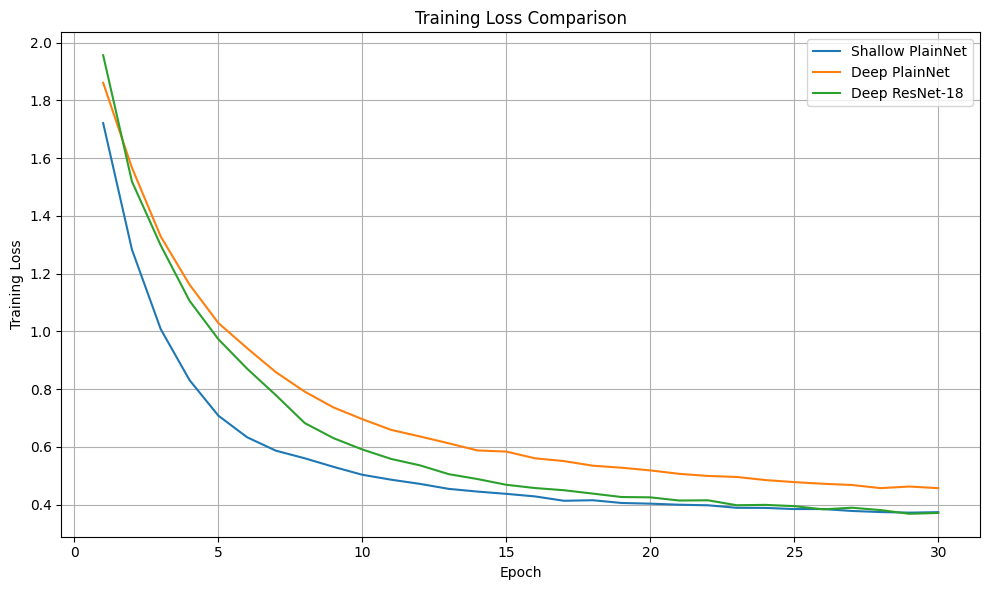

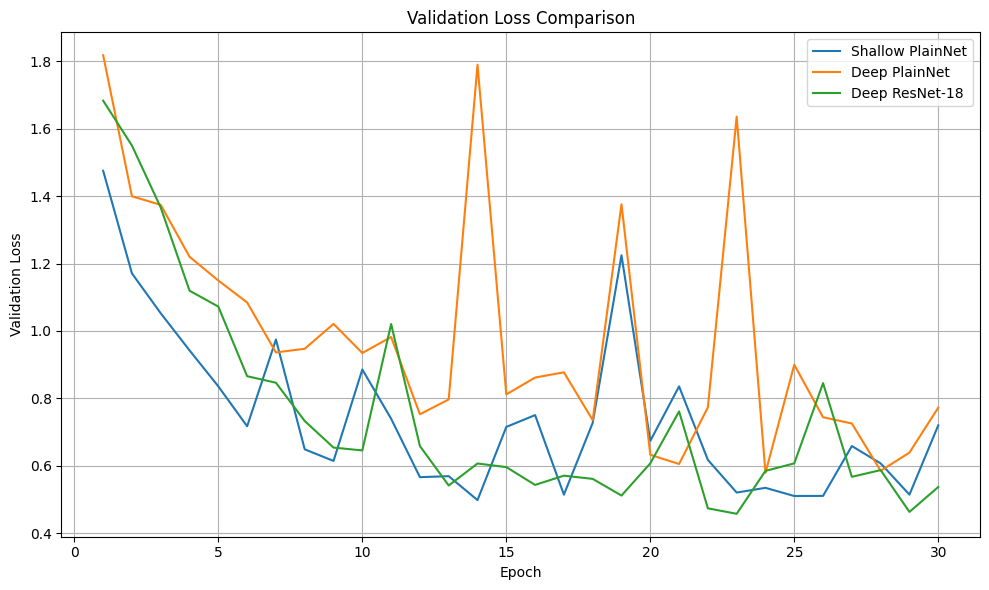

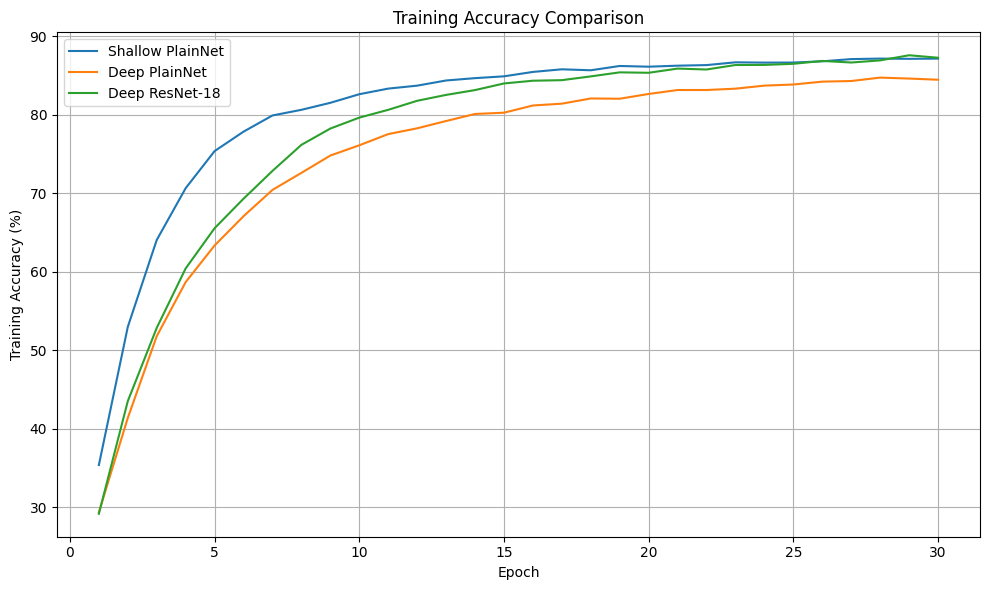

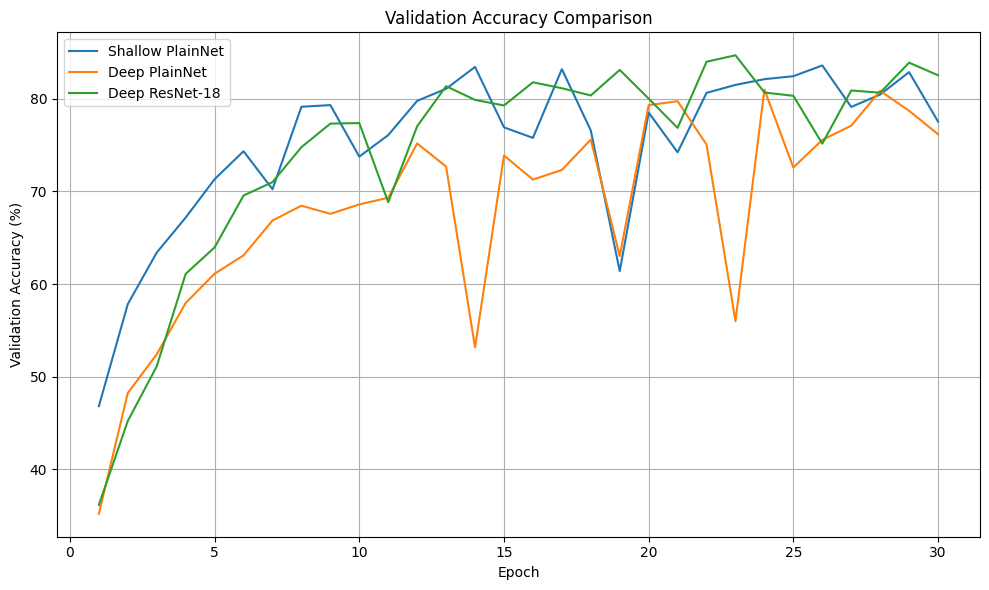

In [30]:
epochs = range(1, EPOCHS + 1)

def plot_metric(histories, metric, ylabel, title, filename):
    plt.figure(figsize=(10, 6))

    for name, history in histories.items():
        plt.plot(
            epochs,
            history[metric],
            label=name
        )

    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(filename, dpi=150)
    plt.show()


plot_metric(
    histories,
    "train_loss",
    "Training Loss",
    "Training Loss Comparison",
    "training_loss.png"
)

plot_metric(
    histories,
    "val_loss",
    "Validation Loss",
    "Validation Loss Comparison",
    "validation_loss.png"
)

plot_metric(
    histories,
    "train_accuracy",
    "Training Accuracy (%)",
    "Training Accuracy Comparison",
    "training_accuracy.png"
)

plot_metric(
    histories,
    "val_accuracy",
    "Validation Accuracy (%)",
    "Validation Accuracy Comparison",
    "validation_accuracy.png"
)


In [31]:
rows = []

for name, history in histories.items():
    best_idx = history["best_epoch"] - 1
    model = trained_models[name]

    rows.append({
        "Model": name,
        "Parameters": sum(
            p.numel() for p in model.parameters()
        ),
        "Final Train Loss": history["train_loss"][-1],
        "Final Train Accuracy (%)":
            history["train_accuracy"][-1],
        "Final Val Loss": history["val_loss"][-1],
        "Final Val Accuracy (%)":
            history["val_accuracy"][-1],
        "Best Val Loss": history["best_val_loss"],
        "Val Accuracy at Best Loss (%)":
            history["val_accuracy"][best_idx],
        "Best Epoch": history["best_epoch"],
        "Total Training Time (s)":
            sum(history["epoch_seconds"])
    })

results_df = pd.DataFrame(rows)

print(results_df.round(4).to_string(index=False))


           Model  Parameters  Final Train Loss  Final Train Accuracy (%)  Final Val Loss  Final Val Accuracy (%)  Best Val Loss  Val Accuracy at Best Loss (%)  Best Epoch  Total Training Time (s)
Shallow PlainNet     4729418            0.3735                   87.1778          0.7200                   77.54         0.4983                          83.44          14                1031.2217
   Deep PlainNet    11000138            0.4565                   84.4844          0.7725                   76.18         0.5793                          81.00          24                1512.6182
  Deep ResNet-18    11173962            0.3707                   87.2889          0.5371                   82.54         0.4577                          84.70          23                1599.4356


In [32]:

test_dataset = datasets.CIFAR10(
    root=cifar_path,
    train=False,
    download=True,
    transform=eval_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

criterion = nn.CrossEntropyLoss()

test_rows = []

for name, model in trained_models.items():
    test_loss, test_accuracy = evaluate(
        model=model,
        data_loader=test_loader,
        criterion=criterion,
        device=device
    )

    test_rows.append({
        "Model": name,
        "Selected Epoch": histories[name]["best_epoch"],
        "Best Validation Loss": histories[name]["best_val_loss"],
        "Test Loss": test_loss,
        "Test Accuracy (%)": test_accuracy
    })

test_df = pd.DataFrame(test_rows)

print(test_df.round(4).to_string(index=False))


           Model  Selected Epoch  Best Validation Loss  Test Loss  Test Accuracy (%)
Shallow PlainNet              14                0.4983     0.4925              83.28
   Deep PlainNet              24                0.5793     0.5949              80.27
  Deep ResNet-18              23                0.4577     0.4596              84.82


In [33]:
for name, history in histories.items():
    print(
        f"{name}: "
        f"best epoch = {history['best_epoch']}, "
        f"best validation loss = {history['best_val_loss']:.4f}"
    )


Shallow PlainNet: best epoch = 14, best validation loss = 0.4983
Deep PlainNet: best epoch = 24, best validation loss = 0.5793
Deep ResNet-18: best epoch = 23, best validation loss = 0.4577


In [35]:
%whos

Variable                 Type                Data/Info
------------------------------------------------------
BasicBlock               type                <class '__main__.BasicBlock'>
DataLoader               type                <class 'torch.utils.data.dataloader.DataLoader'>
EPOCHS                   int                 30
In                       list                n=5
Out                      dict                n=12
PlainBlock               type                <class '__main__.PlainBlock'>
PlainNet                 type                <class '__main__.PlainNet'>
ResNet18                 type                <class '__main__.ResNet18'>
SEED                     int                 42
Subset                   type                <class 'torch.utils.data.dataset.Subset'>
ToTensor                 type                <class 'torchvision.trans<...>rms.transforms.ToTensor'>
ax                       Axes                Axes(0.672794,0.11;0.226471x0.226471)
axes                     ndarray  

In [37]:
print(histories.keys())

for model_name, history in histories.items():
    print(f"\n{model_name}")
    print("Type:", type(history))

    if isinstance(history, dict):
        print("Keys:", history.keys())
    else:
        print(history)

dict_keys(['Shallow PlainNet', 'Deep PlainNet', 'Deep ResNet-18'])

Shallow PlainNet
Type: <class 'dict'>
Keys: dict_keys(['train_loss', 'train_accuracy', 'val_loss', 'val_accuracy', 'epoch_seconds', 'best_epoch', 'best_val_loss'])

Deep PlainNet
Type: <class 'dict'>
Keys: dict_keys(['train_loss', 'train_accuracy', 'val_loss', 'val_accuracy', 'epoch_seconds', 'best_epoch', 'best_val_loss'])

Deep ResNet-18
Type: <class 'dict'>
Keys: dict_keys(['train_loss', 'train_accuracy', 'val_loss', 'val_accuracy', 'epoch_seconds', 'best_epoch', 'best_val_loss'])


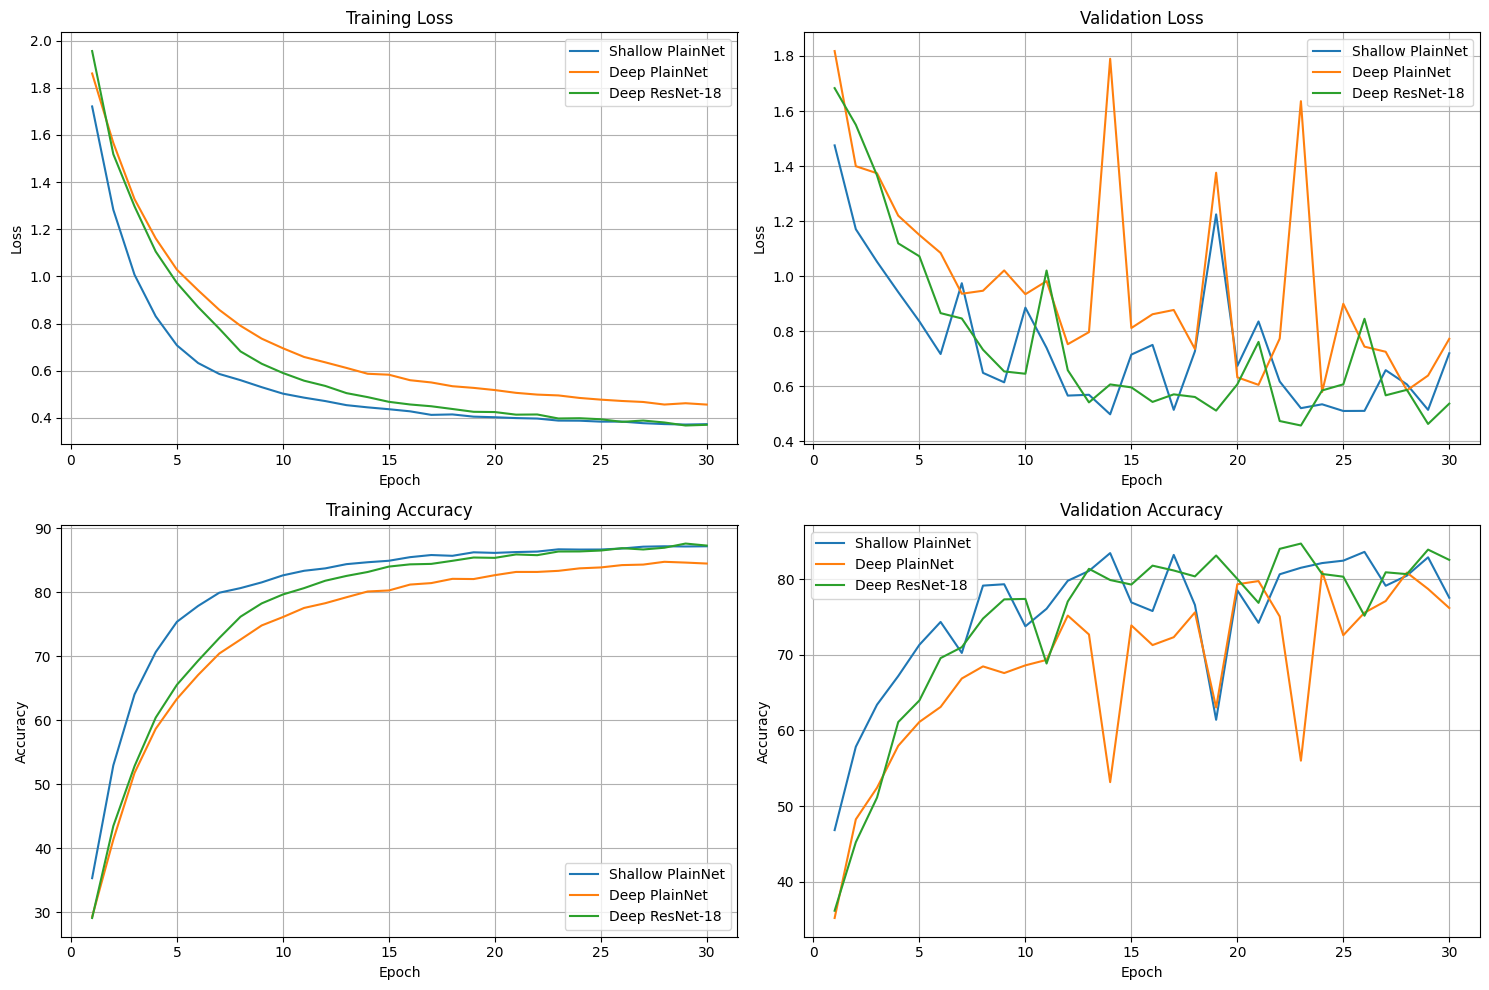

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

metrics = [
    ("train_loss", "Training Loss", axes[0, 0]),
    ("val_loss", "Validation Loss", axes[0, 1]),
    ("train_accuracy", "Training Accuracy", axes[1, 0]),
    ("val_accuracy", "Validation Accuracy", axes[1, 1])
]

for metric, title, ax in metrics:
    for model_name, history in histories.items():
        values = history[metric]
        epochs = range(1, len(values) + 1)

        ax.plot(epochs, values, label=model_name)

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss" if "loss" in metric else "Accuracy")
    ax.grid(True)
    ax.legend()

plt.tight_layout()

plt.savefig(
    "phase6_learning_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Conclusion: ResNet-18 and the Degradation Problem

In this experiment, I implemented and compared three CNN architectures on CIFAR-10: a shallow PlainNet, a deep PlainNet, and ResNet-18. The objective was to investigate whether increasing network depth improves performance and whether residual connections help optimize deeper networks.

The Shallow PlainNet achieved **83.28% test accuracy**, while the Deep PlainNet achieved **80.27%**, despite having more than twice as many parameters. This result is consistent with the degradation problem: increasing network depth did not improve the performance of the plain network in this experiment.

ResNet-18 achieved the highest test accuracy at **84.82%**, outperforming the Deep PlainNet by 4.55 percentage points and the Shallow PlainNet by 1.54 percentage points. Its residual connections provide shortcut paths that help information and gradients flow through the network, making deep architectures easier to optimize.

Overall, the experiment demonstrates that increasing depth alone does not guarantee better performance. Residual connections helped the deeper network achieve better results in this experiment. However, repeated runs with different random seeds would provide stronger evidence that the observed differences are consistent rather than dependent on a single training run.